# 05 — Thương mại gạo quốc tế có bounded scope

Viet Nam reporter, CPC 23161.02 Rice, milled, export flow, 2019–2023. Không full-history semantic validation.

Environment: Windows host, Python 3.10–3.13; `pip install -r requirements/analytics.txt`.
Docker `tlcn-local` đã healthy, Windows available >=2 GiB, WSL >=3 GiB, không active writer/DagRun.
Không start Spark. Mỗi notebook chạy độc lập, theo thứ tự cells. Query names/typed filters hiển thị
trong retrieval cells; kết quả là full scoped results/aggregates, **không phải 20-row sample consumer**.
Source-scoped identities không phải official crosswalk. Không forward-fill/interpolate.

Chạy `python scripts/run_eda_notebooks.py --notebook <filename>` từ repo root để execute và cập nhật
Markdown diễn giải bằng đúng measured evidence. Kết quả Markdown ghi batch cố định bên trên;
publication đổi sẽ fail closed. Không dùng outputs cũ như live query cache.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/gold/consumer.py').exists())
sys.path.insert(0, str(ROOT/'src'))  # repository bootstrap, no credentials
import pandas as pd
import numpy as np
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from analytics.client import EDAClient
from analytics.methods import calendar_yoy, endpoint_change, monthly_calendar
from analytics.notebook import inspect_frame, label, resolve, annual_plot, save_evidence
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
client = EDAClient()
findings = []
inventory = client.query('publication')
EXPECTED_BATCH = 'ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235'
assert client.batch == EXPECTED_BATCH, 'Publication changed: review scope before reproducing EDA'
display(inventory)
print('Published batch:', client.batch, '| No query cache | Windows/WSL/writer gates checked per request')

,table,rows,uuid,snapshot_id
0,dim_date,2038,0d029553-197b-4e46-8d62-17f21334a11b,7665947661409225898
1,dim_month,800,4f262a83-5e36-4d9e-b7e0-18f91b46327f,8295574410069434036
2,dim_observation_type,34,8adc0a9f-498e-4503-aa05-f95ae5a358ed,1046146616745412073
3,dim_price_series,1042,fa39bf1e-bbf1-4b50-8129-de1d4f37413b,2896601742107309180
4,dim_source_geography,987,ce487b86-5541-44de-a006-365dfbcc29f2,8664595598201008097
5,dim_source_product,295,4ce4f42f-e876-4870-8b2a-0312c460d673,8514812747103222137
6,dim_source_system,9,3c9fdb0f-127a-45f4-8f5b-31c7d1d5c0c1,5212267582300439758
7,dim_year,67,032861f7-4c4e-4ac4-9a10-274670b1d694,3316235776078407392
8,fact_fao_price_annual,9993,3218dd14-0793-4c1d-941c-31ba5e1aaea8,6561274137596983252
9,fact_fao_production_observation,22738,f97e800f-ebe6-416c-918a-a148ec0388b4,4557995850181557281


Published batch: ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235 | No query cache | Windows/WSL/writer gates checked per request


## Câu hỏi 1 — Partner-level quantity/value và paired unit values

In [2]:
geos=client.query('catalogue',kind='geographies');products=client.query('catalogue',kind='products')
reporter=resolve(geos,'faostat_m49','704','geography_key')
product=resolve(products,'faostat_cpc','23161.02','product_key')
trade_products=client.query('subject_products',fact='fact_fao_trade_observation',geography=reporter)
display(trade_products)
assert product in set(trade_products.product_key)
trade=client.query('trade',reporter=reporter,product=product,flow='export',start_year=2019,end_year=2023)

,product_key,source_identity,source_labels_json,observations,numeric_observations,first_year,last_year,metric_codes
0,2c420d0f0c2ad660ba4a162fc7daed4a1e486d8239cb24...,23161.03,"[""Rice, broken""]",746,746,2012,2023,"[5922, 5610, 5622, 5910]"
1,47b4dde0c6083d0e2ee5a313603df027c7c03d6ef2f46f...,0113,"[""Rice""]",182,182,2014,2023,"[5922, 5622, 5610, 5910]"
2,9b20a1844ec8b08d320fceaf8f4360279d9a41fa491578...,23161.02,"[""Rice, milled""]",2406,2406,2012,2023,"[5922, 5622, 5910, 5610]"
3,f57f60caf9f1ee0dd52131a6ec1a5caffd6d3438e11e78...,23490.01,"[""Communion wafers, empty cachets of a kind su...",934,934,2014,2023,"[5922, 5910, 5610, 5622]"
4,844aacb2360e662ab96535edc3851bf5e36eef273e03f6...,23162,"[""Husked rice""]",732,732,2012,2023,"[5910, 5622, 5610, 5922]"
5,f5ad2785bf21d045affbb0ac90152d83d6ec2067c176ea...,F0030,"[""Rice, paddy (rice milled equivalent)""]",2478,2478,2012,2023,"[5910, 5922, 5610, 5622]"


In [3]:
display(trade.shape,inspect_frame(trade),trade.head())

(397, 14)

,dtype,nulls
year_key,int64,0
reporter_geography_key,object,0
partner_geography_key,object,0
product_key,object,0
quantity_t,object,0
value_usd,object,0
reported_unit_value_usd_t,object,0
present_quantity,int64,0
present_value,int64,0
observation_quantity,object,0


,year_key,reporter_geography_key,partner_geography_key,product_key,quantity_t,value_usd,reported_unit_value_usd_t,present_quantity,present_value,observation_quantity,observation_value,partner_identity,partner_labels,partner_level
0,2020,454338b3e9b9203015ec55fa27305ffba31eac866ae497...,a260f67e13b6a0dea76bca4204039b53c383ce9730a56b...,9b20a1844ec8b08d320fceaf8f4360279d9a41fa491578...,3578.65,1696000.00,473.92,1,1,23fa3047844f80792ff09f580d10e11ffa3d433ef0cb30...,71c2899a61ce79d0bba173ce17691d055fb5191ba247ec...,024,"[{""label"":""Angola"",""role"":""source""}]",source_area
1,2020,454338b3e9b9203015ec55fa27305ffba31eac866ae497...,b7ca4bd3be6d9c838422aaad4f7aab768cdf9ade182f62...,9b20a1844ec8b08d320fceaf8f4360279d9a41fa491578...,202.42,107000.00,528.60,1,1,8bff79575c649e1cafef89c03e2eb436eee4c35b5453dd...,4def13d8b3d50cdc8009cc8399b1406c1de2dbe9151570...,040,"[{""label"":""Austria"",""role"":""source""}]",source_area
2,2020,454338b3e9b9203015ec55fa27305ffba31eac866ae497...,c23bc438eeedaa8ff5b2b47e2311f0c4986b645cfde34d...,9b20a1844ec8b08d320fceaf8f4360279d9a41fa491578...,551.88,268000.00,485.61,1,1,72508c4335270bd7b327009bbaff9b529a15e9e769b5ab...,fdc51f5a7de62d587b87c209a3f2801eb2eab173bd564d...,056,"[{""label"":""Belgium"",""role"":""source""}]",source_area
3,2020,454338b3e9b9203015ec55fa27305ffba31eac866ae497...,774f49d75cd0b86d418ae0cab35aeb0cfe7131bd830e0c...,9b20a1844ec8b08d320fceaf8f4360279d9a41fa491578...,20.88,17000.00,814.18,1,1,0eebb3ac052e5d5ffd82b0aa3a3c5ef039590825d14d25...,143d33c46a7cb1ec7adcd95ec5d10072630188140d5873...,096,"[{""label"":""Brunei Darussalam"",""role"":""source""}]",source_area
4,2020,454338b3e9b9203015ec55fa27305ffba31eac866ae497...,62ed2f35d6e1b3bd634952f8fabe7d137062a9b278b42c...,9b20a1844ec8b08d320fceaf8f4360279d9a41fa491578...,24.00,13000.00,541.67,1,1,ff7532d79b9a01c08126ff473ce9e0c71cb68922ba52db...,d4ef182c65e2781b012c7c1498621518a96255f72140c9...,112,"[{""label"":""Belarus"",""role"":""source""}]",source_area


In [4]:
for col in ['quantity_t','value_usd','reported_unit_value_usd_t']:trade[col]=pd.to_numeric(trade[col])
assert not trade.duplicated(['year_key','reporter_geography_key','partner_geography_key','product_key']).any()
assert trade.reporter_geography_key.eq(reporter).all() and trade.product_key.eq(product).all()
assert trade.present_quantity.le(1).all() and trade.present_value.le(1).all()
paired=trade.quantity_t.gt(0)&trade.value_usd.notna()
np.testing.assert_allclose(trade.loc[paired,'reported_unit_value_usd_t'],trade.loc[paired,'value_usd']/trade.loc[paired,'quantity_t'],rtol=1e-3,atol=.02)
trade['partner']=trade.partner_labels.map(label)

In [5]:
display(trade.groupby('year_key').agg(groups=('partner','size'),null_quantity=('quantity_t',lambda x:x.isna().sum()),null_value=('value_usd',lambda x:x.isna().sum())))

,groups,null_quantity,null_value
year_key,,,
2019,78,0,0
2020,78,0,0
2021,74,0,0
2022,82,0,0
2023,85,0,0


## Câu hỏi 2 — Selected partner trends (không country-total denominator)

In [6]:
# Explicit reported source identities, not automatically conformed country groups.
selected_identities=['156','608','458']  # China, Philippines, Malaysia catalogue identities checked below
selected=trade[trade.partner_identity.isin(selected_identities)].copy()
display(geos[(geos.identity_namespace=='faostat_m49')&geos.source_identity.isin(selected_identities)])
assert selected.partner_identity.nunique()>=2
display(selected[['year_key','partner_identity','partner','quantity_t','value_usd','reported_unit_value_usd_t']])

,geography_key,identity_namespace,identity_scope,source_identity,source_labels_json,source_level,interpretation_status
36,e7311a44edf092a6ec7898be8a4cfba59cc4b40eac9ff8...,faostat_m49,faostat,156,"[{""label"":""China, mainland"",""role"":""source""}]",source_area,source_identity_only
115,06ec7371ef788c52ade5db97cdd9962bbae16454fde7c2...,faostat_m49,faostat,458,"[{""label"":""Malaysia"",""role"":""source""}]",source_area,source_identity_only
150,571385cf57d58ce447dbdfd085429db0498903f32d283d...,faostat_m49,faostat,608,"[{""label"":""Philippines"",""role"":""source""}]",source_area,source_identity_only


,year_key,partner_identity,partner,quantity_t,value_usd,reported_unit_value_usd_t
26,2020,156,"China, mainland",501791.49,2.448950e+08,488.04
54,2022,458,Malaysia,436544.80,1.981320e+08,453.86
86,2023,156,"China, mainland",753672.54,4.460440e+08,591.83
96,2023,458,Malaysia,400504.18,2.021540e+08,504.75
128,2019,156,"China, mainland",347012.45,1.791820e+08,516.36
144,2019,608,Philippines,2129613.10,8.837040e+08,414.96
167,2021,156,"China, mainland",622491.50,3.224610e+08,518.02
196,2021,608,Philippines,2396191.90,1.226776e+09,511.97
222,2020,458,Malaysia,554980.89,2.362550e+08,425.70
226,2020,608,Philippines,2213662.42,1.045804e+09,472.43


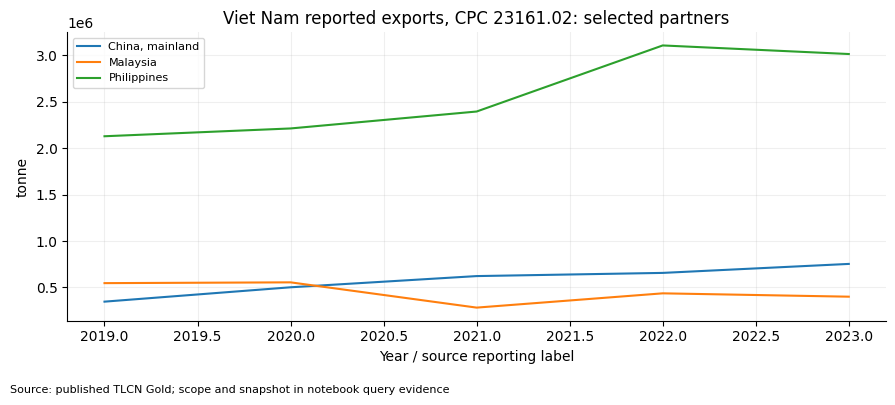

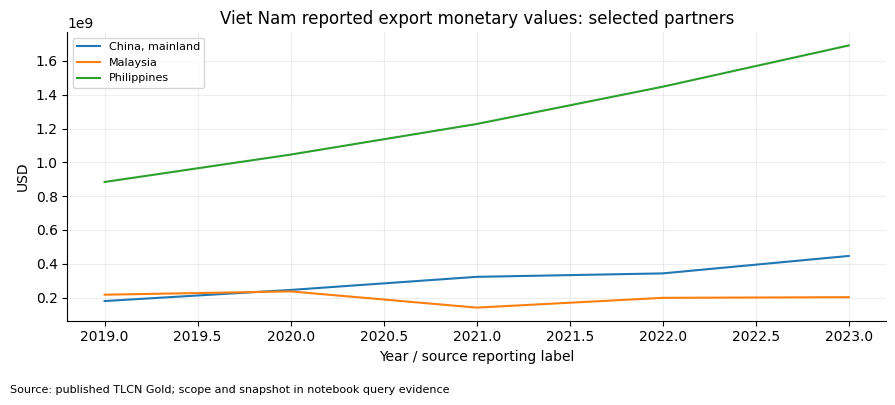

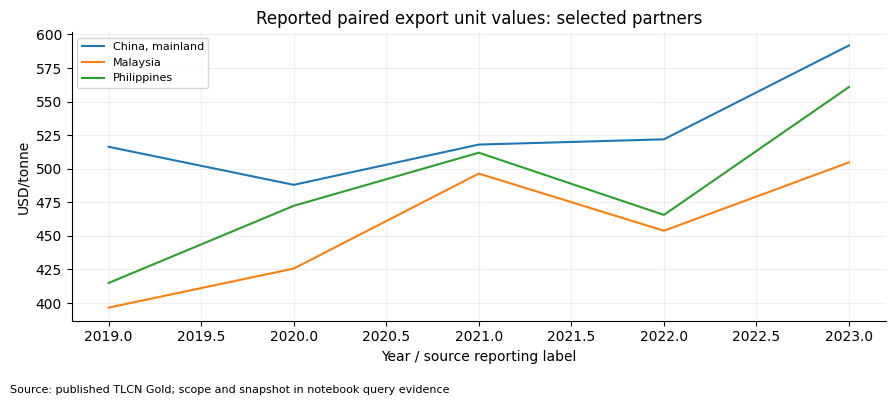

In [7]:
annual_plot(selected,'quantity_t','Viet Nam reported exports, CPC 23161.02: selected partners','tonne',group='partner')
annual_plot(selected,'value_usd','Viet Nam reported export monetary values: selected partners','USD',group='partner')
annual_plot(selected,'reported_unit_value_usd_t','Reported paired export unit values: selected partners','USD/tonne',group='partner')

**Nguồn biểu đồ:** published TLCN Gold, batch `ec421297…`. Exact source table/metric/series, units và time filters ở retrieval/validation cells ngay trong section này. Không có interpolation hoặc tự chuyển source identities.

**Diễn giải:** Không cộng reporter mirror flows hoặc partner breakdown với country totals. Unit value là ratio reported value/quantity, không observed market price; không AVG row-level unit values.

In [8]:
for index,(partner,d) in enumerate(selected.groupby('partner')):
    stat=endpoint_change(d,value='quantity_t')
    findings.append(dict(id=f'TR{index+1:02d}',title='Bilateral reported quantity — '+partner,
      observation=f"{stat['first_year']}–{stat['last_year']}: {stat['first_value']:,.2f} → {stat['last_value']:,.2f} tonnes ({stat['change_pct']:+.2f}%).",
      scope='Viet Nam reporter; CPC 23161.02; export; exact selected partner identity',interpretation='Bilateral reported change; không suy global exporter rank, mirror reconciliation hoặc price causality.',query='trade',cell='Câu hỏi 2',numbers=stat))
uv_series=selected[selected.partner_identity=='608']
uv=endpoint_change(uv_series,value='reported_unit_value_usd_t')
findings.append(dict(id='TR04',title='Reported unit value sang Philippines',observation=f"{uv['first_year']}–{uv['last_year']}: {uv['first_value']:,.2f} → {uv['last_value']:,.2f} USD/tonne ({uv['change_pct']:+.2f}%).",scope='Viet Nam reporter / partner M49 608 / CPC 23161.02 / export; value-quantity pairing',interpretation='Có thể phản ánh composition/contract/reporting effects; không phải independent market price hoặc causal inflation estimate.',query='trade',cell='Câu hỏi 2',numbers=uv))

## Câu hỏi 3 — Lượng hàng và unit value có association nào đáng khảo sát?

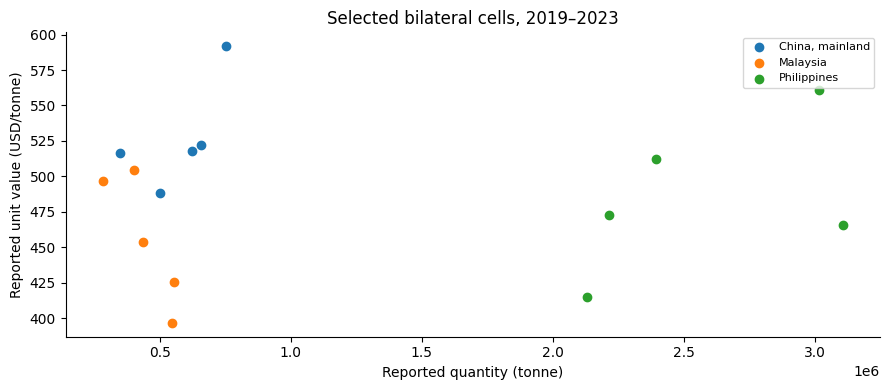

,query,row_count,query_seconds,response_bytes
0,publication,17,0.000000,4333
1,catalogue,987,0.058965,280734
2,catalogue,295,0.044146,49096
3,subject_products,6,0.406535,5057
4,trade,397,0.592698,188726


In [9]:
scatter=selected[selected.quantity_t.gt(0)&selected.reported_unit_value_usd_t.notna()].copy()
fig,ax=plt.subplots(figsize=(9,4))
for partner,d in scatter.groupby('partner'):ax.scatter(d.quantity_t,d.reported_unit_value_usd_t,label=partner)
ax.set(xlabel='Reported quantity (tonne)',ylabel='Reported unit value (USD/tonne)',title='Selected bilateral cells, 2019–2023');ax.legend(fontsize=8)
fig.tight_layout();plt.show();plt.close(fig)
display(pd.DataFrame(client.evidence)[['query','row_count','query_seconds','response_bytes']])

**Nguồn biểu đồ:** published TLCN Gold, batch `ec421297…`. Exact source table/metric/series, units và time filters ở retrieval/validation cells ngay trong section này. Không có interpolation hoặc tự chuyển source identities.

**Diễn giải:** Ít bilateral-year cells, không causal claim. Partner shares/concentration được DEFER vì Gold source_area chưa có verified non-overlapping partner universe/denominator; không tạo share bằng cách bỏ World/unspecified theo cảm tính.

## Key Findings

Measured batch `ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235`.

### TR01 — Bilateral reported quantity — China, mainland

**OBSERVATION:** 2019–2023: 347,012.45 → 753,672.54 tonnes (+117.19%).

**Scope:** Viet Nam reporter; CPC 23161.02; export; exact selected partner identity

**INTERPRETATION / LIMITATION:** Bilateral reported change; không suy global exporter rank, mirror reconciliation hoặc price causality.

**Reproduce:** query `trade`, Câu hỏi 2.

### TR02 — Bilateral reported quantity — Malaysia

**OBSERVATION:** 2019–2023: 546,516.60 → 400,504.18 tonnes (-26.72%).

**Scope:** Viet Nam reporter; CPC 23161.02; export; exact selected partner identity

**INTERPRETATION / LIMITATION:** Bilateral reported change; không suy global exporter rank, mirror reconciliation hoặc price causality.

**Reproduce:** query `trade`, Câu hỏi 2.

### TR03 — Bilateral reported quantity — Philippines

**OBSERVATION:** 2019–2023: 2,129,613.10 → 3,015,899.86 tonnes (+41.62%).

**Scope:** Viet Nam reporter; CPC 23161.02; export; exact selected partner identity

**INTERPRETATION / LIMITATION:** Bilateral reported change; không suy global exporter rank, mirror reconciliation hoặc price causality.

**Reproduce:** query `trade`, Câu hỏi 2.

### TR04 — Reported unit value sang Philippines

**OBSERVATION:** 2019–2023: 414.96 → 560.88 USD/tonne (+35.16%).

**Scope:** Viet Nam reporter / partner M49 608 / CPC 23161.02 / export; value-quantity pairing

**INTERPRETATION / LIMITATION:** Có thể phản ánh composition/contract/reporting effects; không phải independent market price hoặc causal inflation estimate.

**Reproduce:** query `trade`, Câu hỏi 2.

## Limitations

Không global totals/rankings, mirror double count, product mixing hoặc cross-reporter price comparisons. Partner concentration cần approved universe. Bộ query chỉ bao phủ selected reporter/product/flow/5 years, không toàn 39 năm.

In [10]:
print(save_evidence(ROOT, '05_international_rice_trade', client, findings))
print('Query audit:')
display(pd.DataFrame(client.evidence)[['query','row_count','query_seconds','response_bytes','batch']])

docs/analytics/evidence/05_international_rice_trade.json
Query audit:


,query,row_count,query_seconds,response_bytes,batch
0,publication,17,0.000000,4333,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
1,catalogue,987,0.058965,280734,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
2,catalogue,295,0.044146,49096,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
3,subject_products,6,0.406535,5057,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
4,trade,397,0.592698,188726,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
